# Cohort construction on twelve Gold members: who entered when?

**Week 4, Thursday, SECTION 5, the first case notebook (L1, counted by hand).** It applies
Cohort construction, which notebook 01 taught on an invented gym: fix the month each member
joined, leave that month out as month zero, and compare every group at the same age, since one
calendar month mixes ages.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for
> this class.*

**The ticket. Zomato Gold, Chennai, the membership and the app's order flow.** Zomato Gold is the
food-delivery app's paid membership, whose members get free delivery (Zomato's shareholder letter of
19 May 2023, checked 12 October 2026). The membership dashboard reports month-two retention for
Chennai, the share of members two or more months past their signup month who ordered in the month,
as flat at 38 percent for June, July, August and September 2026. A member who places no order in a
month is not retained that month; she is still a member and may order again. A **cohort** is the
members who joined in the same month. Each cohort's own curve falls with age, and each cohort's
month-one rate is lower than the one before: January 58 percent, April 53, July 49, and August 31.
The August cohort, 13,000 members, 2.6 times the 5,000 a month of January to July, grew out of a
sale week with a discounted first month. On Monday 14 September 2026 a new checkout flow shipped on
Android; since then members' add-to-cart to order conversion on Android fell from 58 to 44 percent,
while members on iOS went from 57 to 56 and non-members on Android from 52 to 51. **The ask, due
Friday:** is it a cohort problem (members who joined in some months order less than members who
joined in others) or an everyone problem (members of every signup month changed at once), which
funnel stage owns the loss, and what should be fixed first, with the evidence.

**Who needs the answer.** The membership lead, who reads the dashboard every month and has to
say on Friday whether Gold has a cohort problem or an everyone problem. A wrong call sends the
fix to the wrong place.

**The questions on the way.**

1. Which of the twelve members ordered in each month since they joined?
2. What does each signup group keep, month one, month two and on?
3. What does the dashboard's way of counting say about the twelve, and what does it leave out?

In [1]:
# Load the twelve members SECTION 5 counts, and the full tables to prove they are real rows.
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print(("PASS  " if ok else "FAIL  ") + name)

cols = ["ordered_in_jun", "ordered_in_jul", "ordered_in_aug", "ordered_in_sep"]
twelve = pd.read_csv("../data/C2_W04_D04_twelve_rows_STUDENT.csv", dtype={c: "Int64" for c in cols})
members = pd.read_csv("../data/C2_W04_D04_members_STUDENT.csv")
member_months = pd.read_csv("../data/C2_W04_D04_member_months_STUDENT.csv")
print(f"{len(twelve)} members on the card; {len(members):,} members and "
      f"{len(member_months):,} member-months in the full tables")

12 members on the card; 53,089 members and 241,492 member-months in the full tables


## Which of the twelve members ordered in each month since they joined?

The card holds twelve members picked from the case data, which is synthetic like all of it,
to show the pattern on one page: four who joined in May, three in June and five who joined in
the August sale week on its discount. On all 53,089 members (notebook 06), May's month one is
52 percent and June's 50. A cell is 1 when the member placed at least one order that calendar
month and 0 when she placed none. A blank cell is a month before she joined, or the
month she joined, which is month zero and is never counted. **Month one** is the first full
calendar month after the signup month, so May's month one is June and August's is September.

In [2]:
# The card as the data holds it, a blank where the month is not counted for that member.
twelve.astype(object).where(twelve.notna(), "")

,member_id,signup_month,signup_channel,ordered_in_jun,ordered_in_jul,ordered_in_aug,ordered_in_sep
0,ZG20844,May,organic,1,1,1,1
1,ZG21052,May,organic,1,1,0,0
2,ZG22010,May,organic,1,0,0,0
3,ZG22634,May,organic,0,0,0,0
4,ZG25312,Jun,organic,,1,1,1
5,ZG27475,Jun,organic,,1,0,0
6,ZG28603,Jun,organic,,0,0,0
7,ZG39559,Aug,sale,,,,0
8,ZG40539,Aug,sale,,,,0
9,ZG41000,Aug,sale,,,,0


**How the next cell counts by age.** `melt` turns the card from one row per member, with a
column per month, into one row per member per month, so each row can carry its own age, as
notebook 01 did with the gym's register. Each month gets its place among June to September:
June 0, July 1, August 2, September 3. A signup month gets a place on the same scale, so May,
the month before June, is -1, June is 0 and August is 2. Age is the month's place minus the
signup month's: for a May member, June is 0 - (-1) = 1, her month one. One `pivot_table` with
two functions, `sum` and `count`, then gives two tables side by side: how many ordered at each
age, and how many were counted.

**Predict before you run.** Read by months since joining rather than by calendar month, which
group keeps the largest share in its own month one?

- a) The May members
- b) The June members
- c) The August sale-week members
- d) All three keep the same share

In [3]:
# One row per member per month, and her age that month: month k is the k-th month after joining.
months = ["jun", "jul", "aug", "sep"]
joined_at = {"May": -1, "Jun": 0, "Aug": 2}      # where each signup month sits among jun to sep
long = twelve.melt(id_vars=["member_id", "signup_month", "signup_channel"],
                   var_name="month", value_name="ordered").dropna()
long["month"] = long["month"].str[-3:]
long["ordered"] = long["ordered"].astype(int)
long["age"] = long["month"].map(months.index) - long["signup_month"].map(joined_at)
by_age = long.pivot_table(index="signup_month", columns="age", values="ordered",
                          aggfunc=["sum", "count"], sort=False)
kept = by_age["sum"]
check("May keeps 3, 2, 1, 1 of 4", list(kept.loc["May", [1, 2, 3, 4]]) == [3, 2, 1, 1])
check("June keeps 2, 1, 1 of 3", list(kept.loc["Jun", [1, 2, 3]]) == [2, 1, 1])
check("August keeps 0 of 5 in month one", kept.loc["Aug", 1] == 0)
full = member_months.assign(ordered=member_months["orders"].gt(0).astype(int),
                            month=member_months["month"].map({"2026-06": "jun", "2026-07": "jul",
                                                              "2026-08": "aug", "2026-09": "sep"}))
same = long.merge(full, on=["member_id", "month"], suffixes=("_card", "_data"))
check("every card cell is the member's real month in member_months",
      len(same) == len(long) and (same["ordered_card"] == same["ordered_data"]).all())
shown = by_age["sum"].astype("Int64").astype(str) + " of " + by_age["count"].astype("Int64").astype(str)
shown.where(by_age["count"].notna(), "").rename(columns={k: f"month {k}" for k in shown.columns})

PASS  May keeps 3, 2, 1, 1 of 4
PASS  June keeps 2, 1, 1 of 3
PASS  August keeps 0 of 5 in month one


PASS  every card cell is the member's real month in member_months


age,month 1,month 2,month 3,month 4
signup_month,,,,
May,3 of 4,2 of 4,1 of 4,1 of 4
Jun,2 of 3,1 of 3,1 of 3,
Aug,0 of 5,,,


**What happened.** The answer is a. The May members kept 3 of 4 in month one, the June members
2 of 3 and the August sale-week members 0 of 5. Each group falls as it ages: May runs 3, 2, 1,
1 of 4, and June runs 2, 1, 1 of 3. Each later group also starts lower. Fixing the entry
moment, the month a member joined, is what lets the three be compared at all. Drawn by age, as
notebook 01 drew the gym's batches:

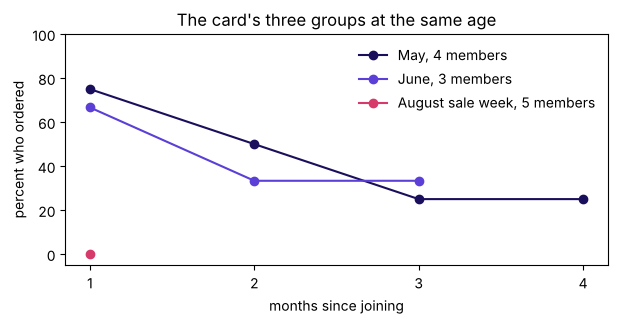

In [4]:
# Each signup group's share by age: every group falls, and each later group starts lower.
share = by_age["sum"] / by_age["count"]
names = {"May": "May, 4 members", "Jun": "June, 3 members", "Aug": "August sale week, 5 members"}
fig, ax = plt.subplots(figsize=(7.0, 3.0))
for g, colour in [("May", "#1A0F5C"), ("Jun", "#5B3FD6"), ("Aug", "#D63A6A")]:
    row = share.loc[g].dropna()
    ax.plot(row.index, 100 * row.values, marker="o", color=colour, label=names[g])
ax.set_xticks(range(1, 5)); ax.set_xlabel("months since joining"); ax.set_ylabel("percent who ordered")
ax.set_ylim(-5, 100); ax.legend(frameon=False)
ax.set_title("The card's three groups at the same age"); plt.show()

## What does the dashboard's way of counting say about the twelve, and what does it leave out?

The dashboard counts a member from her second month after joining: in each reporting month, it
takes every member two or more months past her signup month and asks what share ordered. **Predict
before you run.** On the twelve, what does the dashboard's way read in August and in September?

- a) It falls from August to September, because the sale-week members ordered so little
- b) It reads 2 of 7 in both months, and the five sale-week members are not in it
- c) It rises, because the sale-week members are new
- d) It reads 2 of 12 in both months

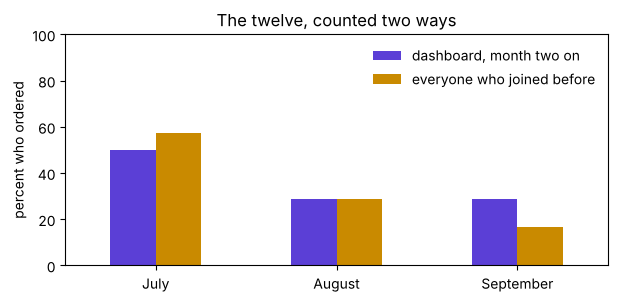

,jul,aug,sep
"dashboard, month two on",2 of 4,2 of 7,2 of 7
everyone who joined before,4 of 7,2 of 7,2 of 12


In [5]:
# Each reporting month counted two ways: from month two on (the dashboard), and everyone.
ways, shares = {}, {}
for m in ["jul", "aug", "sep"]:
    dash = long[(long["month"] == m) & (long["age"] >= 2)]
    every = long[(long["month"] == m) & (long["age"] >= 1)]
    ways[m] = {"dashboard, month two on": f'{dash["ordered"].sum()} of {len(dash)}',
               "everyone who joined before": f'{every["ordered"].sum()} of {len(every)}'}
    shares[m] = {"dashboard, month two on": 100 * dash["ordered"].mean(),
                 "everyone who joined before": 100 * every["ordered"].mean()}
ax = pd.DataFrame(shares).T.plot.bar(figsize=(7.0, 3.0), rot=0, color=["#5B3FD6", "#C98A00"])
ax.set_xticklabels(["July", "August", "September"]); ax.set_ylabel("percent who ordered")
ax.set_ylim(0, 100); ax.legend(frameon=False)
ax.set_title("The twelve, counted two ways"); plt.show()
pd.DataFrame(ways)

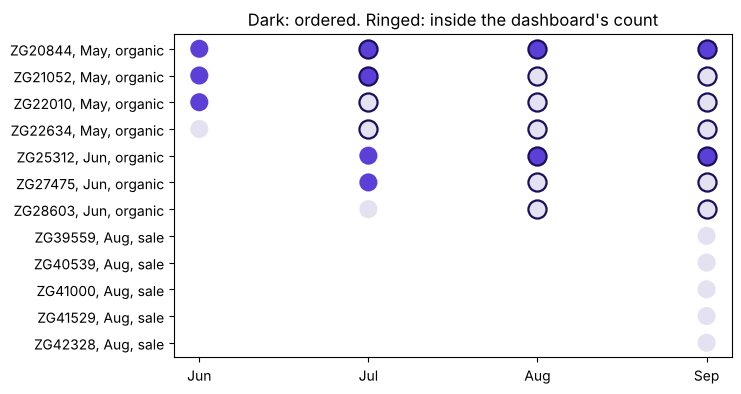

PASS  the dashboard's way reads 2 of 7 in August and in September
PASS  everyone who joined before September: 2 of 12 ordered


In [6]:
# The card drawn: dark when she ordered, ringed when the dashboard counts her that month.
fig, ax = plt.subplots(figsize=(7.2, 4.2))
rows = {mid: i for i, mid in enumerate(twelve["member_id"])}
for _, r in long.iterrows():
    ax.scatter(months.index(r["month"]), -rows[r["member_id"]], s=170,
               c="#5B3FD6" if r["ordered"] == 1 else "#E4E1F1",
               edgecolors="#1A0F5C" if r["age"] >= 2 else "none", linewidths=1.6)
ax.set_xticks(range(4), ["Jun", "Jul", "Aug", "Sep"])
ax.set_yticks([-i for i in range(len(twelve))],
              [f"{mid}, {m}, {ch}" for mid, m, ch in
               zip(twelve["member_id"], twelve["signup_month"], twelve["signup_channel"])])
ax.set_title("Dark: ordered. Ringed: inside the dashboard's count"); plt.show()
check("the dashboard's way reads 2 of 7 in August and in September",
      ways["aug"]["dashboard, month two on"] == ways["sep"]["dashboard, month two on"] == "2 of 7")
check("everyone who joined before September: 2 of 12 ordered", ways["sep"]["everyone who joined before"] == "2 of 12")

**What happened.** The answer is b. Counted the dashboard's way, 2 of 7 members ordered in
August and 2 of 7 in September: the number did not move, though five new members arrived and
none of them ordered. They are outside the count until their second month, October.
Counting everyone who joined before September gives 2 of 12. On the full data, notebook 06
finds the same two readings: 38 percent the dashboard's way, 36 counting everyone, and takes
the 38 apart as notebook 03 took the gym's dashboard apart.

**The questions, answered.** (1) The card shows who ordered each month; blanks are months
before or at joining. (2) May kept 3, 2, 1, 1 of 4, June 2, 1, 1 of 3, and the August sale week
0 of 5 in month one. (3) The dashboard's way read 2 of 7 in August and in September, with the
five sale-week members outside its count.